In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, sosfiltfilt, argrelextrema
from scipy.interpolate import CubicSpline
from PyEMD import EMD
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, periodogram, get_window

# Methods

## 1. Empirical Mode Decomposition (EMD)

- Proposed by Huang et al. (1998) in "The Empirical Mode Decomposition and the Hilbert Spectrum for Nonlinear and Non-Stationary Time Series Analysis."
- Decomposes the signal into Intrinsic Mode Functions (IMFs) by sifting, from the fastest oscillation to the slowest.

### **Process:**
1. Identify all local maxima and minima of the signal.
2. Connect the maxima with a cubic spline to form the upper envelope, and the minima to form the lower envelope.
3. Compute the mean of the two envelopes.
4. Subtract this mean from the signal.
5. Repeat steps 1 to 4 on the result until it satisfies the two IMF conditions. This is the first IMF.
6. Subtract the IMF from the original signal and repeat the whole process on the remainder to extract the next IMF.

### **IMF conditions:**
1. The number of extrema (maxima plus minima) and the number of zero crossings differ by at most one.
2. The local mean is zero at every instant.

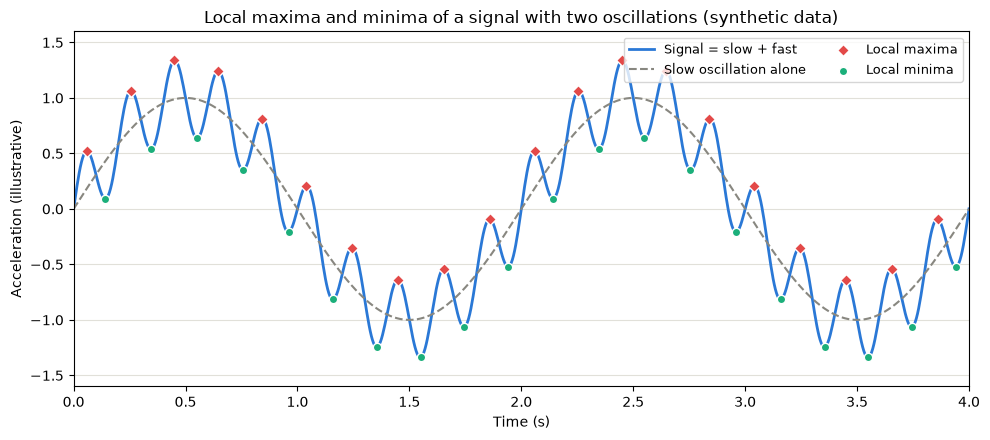

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Signal parameters
fs = 200          # sampling frequency (Hz)
duration = 4.0    # signal length (s)
a_slow, f_slow = 1.0, 0.5    # slow oscillation: amplitude, frequency (Hz)
a_fast, f_fast = 0.35, 5.0   # fast oscillation: amplitude, frequency (Hz)

# Sampled time vector and signal
t = np.arange(0, duration + 1 / fs, 1 / fs)
x_slow = a_slow * np.sin(2 * np.pi * f_slow * t)
x_fast = a_fast * np.sin(2 * np.pi * f_fast * t)
x = x_slow + x_fast

# Local extrema: compare each sample with its neighbors
is_max = (x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:])
is_min = (x[1:-1] < x[:-2]) & (x[1:-1] <= x[2:])
idx_max = np.where(is_max)[0] + 1
idx_min = np.where(is_min)[0] + 1

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(t, x, color="#2a78d6", lw=2, label="Signal = slow + fast")
ax.plot(t, x_slow, color="#888780", lw=1.5, ls="--", label="Slow oscillation alone")
ax.scatter(t[idx_max], x[idx_max], marker="D", s=36, color="#e34948",
           edgecolor="white", zorder=3, label="Local maxima")
ax.scatter(t[idx_min], x[idx_min], marker="o", s=36, color="#1baf7a",
           edgecolor="white", zorder=3, label="Local minima")

ax.set_title("Local maxima and minima of a signal with two oscillations (synthetic data)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Acceleration (illustrative)")
ax.set_xlim(0, duration)
ax.set_ylim(-1.6, 1.6)
ax.grid(axis="y", color="#e1e0d9")
ax.legend(loc="upper right", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

There is one maximum and one minimum per cycle of the fast oscillation. The slow oscillation does not create peaks of its own: it only raises and lowers the height at which the peaks of the fast one fall.

In Python, the `PyEMD` library can be used to apply the method and decompose a signal into its IMFs.

### **Limitations:**
- Mode mixing: when two oscillations vibrate at close frequencies, the EMD can mix both into a single IMF.
- Modes split across IMFs: when an oscillation is intermittent, one vibration mode can be split into two IMFs.
- Malekjafarian et al. (2017) showed that if the excitation makes the target mode resonate, that mode dominates the signal and the EMD easily separates it into one IMF.

### **Example:**

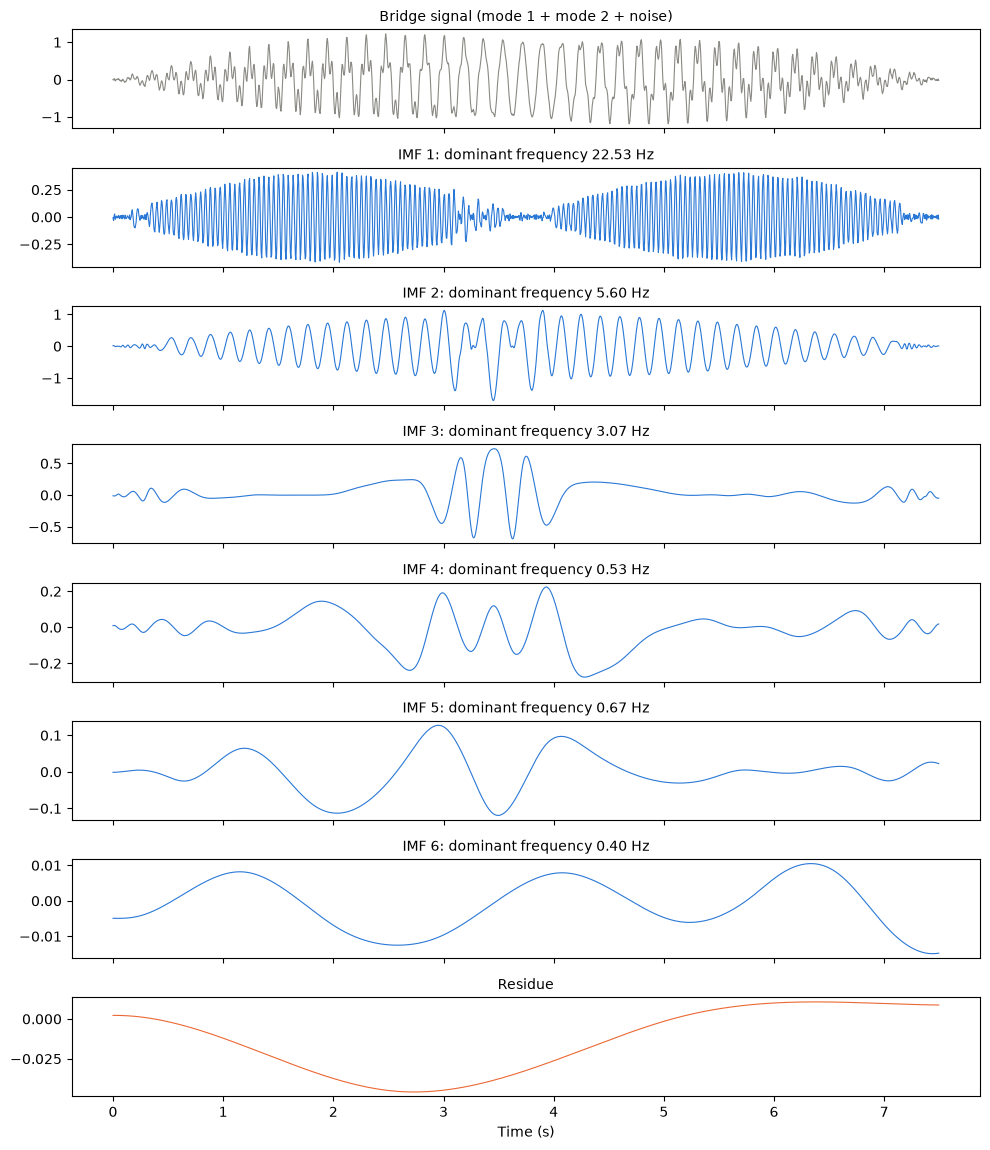

In [3]:
# Colors (same roles as in metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)

# Shared example: vehicle crossing a simply supported bridge
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

rng = np.random.default_rng(42)   # fixed seed for the noise

# Bridge signal: mode 1 + mode 2 + small noise
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.02 * rng.standard_normal(t.size))


def dominant_frequency(x, fs):
    # Frequency of the largest FFT peak (ignoring 0 Hz)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


emd = EMD()
emd.emd(x_bridge, t)
imfs, residue = emd.get_imfs_and_residue()

n_rows = imfs.shape[0] + 2
fig, axes = plt.subplots(n_rows, 1, figsize=(10, 1.45 * n_rows), sharex=True)
axes[0].plot(t, x_bridge, color=COLOR_SIGNAL, linewidth=0.8)
axes[0].set_title("Bridge signal (mode 1 + mode 2 + noise)", fontsize=10)
for i, imf in enumerate(imfs):
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=0.8)
    axes[i + 1].set_title(f"IMF {i + 1}: dominant frequency {dominant_frequency(imf, FS):.2f} Hz",
                          fontsize=10)
axes[-1].plot(t, residue, color=COLOR_2, linewidth=0.8)
axes[-1].set_title("Residue", fontsize=10)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

<div style="break-before: page; page-break-before: always;"></div>

## 2. PSD from the autocorrelation and the Fourier transform

- Based on the Wiener-Khinchin theorem (Wiener, 1930; Khinchin, 1934): the PSD is the Fourier transform of the autocorrelation.
- Covered in CIV E 789: autocorrelation in session 5 (Lecture 3, slides 20 to 23) and the PSD as the transform of the autocorrelation in session 7 (Lecture 4, slide 22).
- The autocorrelation measures how similar the signal is to itself shifted by a time $\tau$. Taking it to the frequency domain with the Fourier transform gives the PSD.

$$S_{xx}(f) = \int_{-\infty}^{\infty} R_{xx}(\tau)\, e^{-j2\pi f\tau}\, d\tau$$

- $S_{xx}(f)$: PSD of the signal $x$ at frequency $f$.
- $R_{xx}(\tau)$: autocorrelation of $x$ for a lag $\tau$.
- $e^{-j2\pi f\tau}$: the Fourier transform, which compares the autocorrelation with an oscillation of frequency $f$.

### **Process:**
1. Remove the mean of the signal.
2. Compute the autocorrelation for all time lags.
3. Compute the Fourier transform of the autocorrelation.

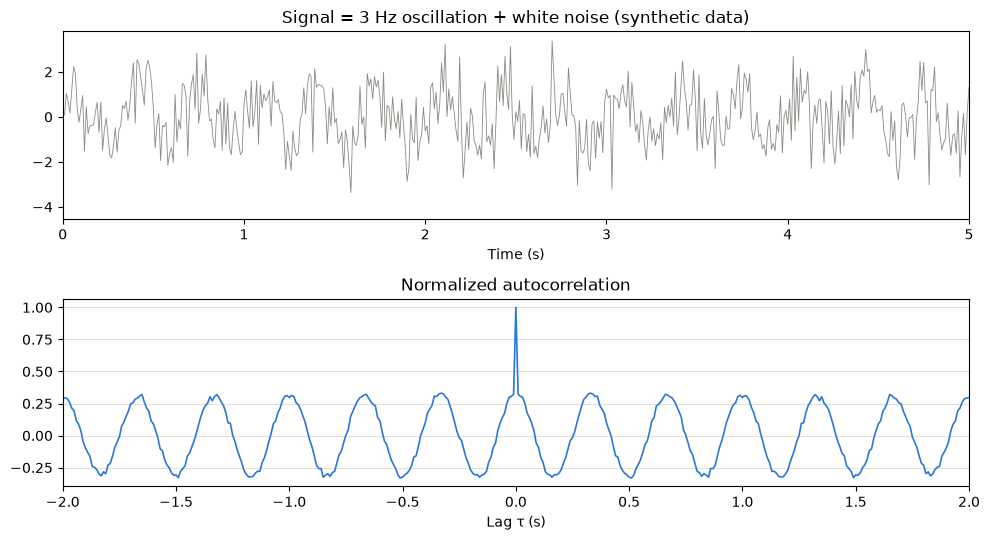

In [4]:
fs = 100.0         # sampling frequency (Hz)
duration = 20.0    # signal length (s)
f0 = 3.0           # tone frequency (Hz)

rng = np.random.default_rng(0)
t = np.arange(0, duration, 1 / fs)
x = np.sin(2 * np.pi * f0 * t) + 1.0 * rng.standard_normal(t.size)
x = x - x.mean()

# Biased autocorrelation (divided by N), normalized so that R(0) = 1
r = np.correlate(x, x, mode="full") / x.size
lags = np.arange(-x.size + 1, x.size) / fs
r = r / r[x.size - 1]

fig, (ax_sig, ax_r) = plt.subplots(2, 1, figsize=(10, 5.5))
ax_sig.plot(t, x, color="#8a8984", lw=0.6)
ax_sig.set_title("Signal = 3 Hz oscillation + white noise (synthetic data)")
ax_sig.set_xlabel("Time (s)")
ax_sig.set_xlim(0, 5)
ax_r.plot(lags, r, color="#2a78d6", lw=1.2)
ax_r.set_title("Normalized autocorrelation")
ax_r.set_xlabel("Lag τ (s)")
ax_r.set_xlim(-2, 2)
ax_r.grid(axis="y", color="#e1e0d9")
plt.tight_layout()
plt.show()

The oscillation is barely visible in the signal, but it is clear in the autocorrelation: the white noise only contributes a peak at $\tau = 0$, while the 3 Hz oscillation leaves a cosine that repeats every 0.33 s. Its Fourier transform gives a peak at 3 Hz.

In Python, the autocorrelation is computed with `np.correlate(x, x, mode="full")` or `scipy.signal.correlate`, and the transform with `np.fft.fft`.

### **Main uses:**
- Obtain the PSD and, from it, the natural frequencies (the peaks).
- The cross-correlation between sensors gives the cross-PSDs used by the FDD.
- It is the basis of ambient-vibration identification methods that work with correlations, such as NExT.

### **Limitations:**
- The result is exactly the periodogram ($|FFT|^2$ of the whole signal), so it fluctuates just as much.
- Large lags are computed with few samples and are unreliable.

### **Example:**

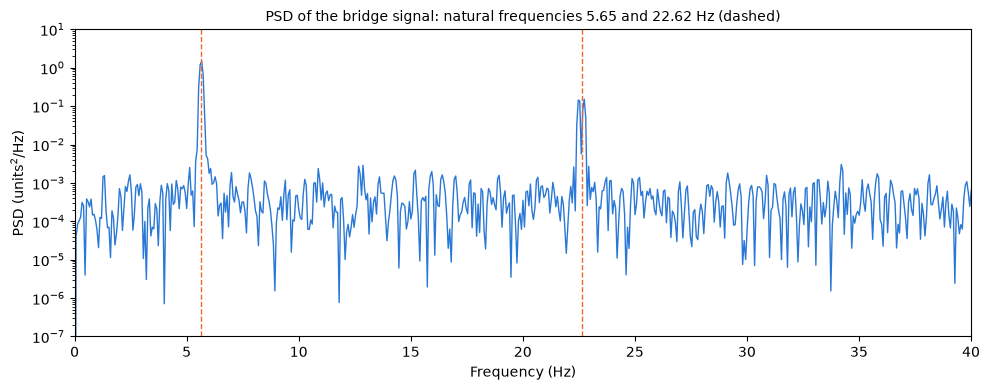

In [5]:
# Colors (same roles as in metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)

# Shared example: vehicle crossing a simply supported bridge
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

rng = np.random.default_rng(42)   # fixed seed for the noise

# Bridge signal: mode 1 + mode 2 + noise
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.2 * rng.standard_normal(t.size))
x_bridge = x_bridge - x_bridge.mean()
N = x_bridge.size


def psd_from_autocorr(r_full, fs, n_fft):
    # One-sided PSD = Fourier transform of the autocorrelation (lags -(N-1)...(N-1))
    r_circ = np.fft.ifftshift(r_full)              # put lag 0 first
    s = np.real(np.fft.fft(r_circ, n_fft)) / fs    # two-sided PSD (units^2/Hz)
    f = np.fft.rfftfreq(n_fft, 1 / fs)
    s_one = s[:f.size].copy()
    last = -1 if n_fft % 2 == 0 else None          # Nyquist bin exists only for even n_fft
    s_one[1:last] *= 2                             # one-sided: double all bins except 0 Hz and Nyquist
    return f, s_one


r_full = np.correlate(x_bridge, x_bridge, mode="full") / N   # biased autocorrelation
n_fft = 2 * N - 1

# PSD = Fourier transform of the autocorrelation
f_ac, s_ac = psd_from_autocorr(r_full, FS, n_fft)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_ac, s_ac, color=COLOR_1, lw=1)
for f_n in (F1, F2):
    ax.axvline(f_n, color=COLOR_2, ls="--", lw=1)
ax.set_title("PSD of the bridge signal: natural frequencies 5.65 and 22.62 Hz (dashed)", fontsize=10)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (units$^2$/Hz)")
ax.set_xlim(0, 40)
ax.set_ylim(1e-7, 10)
fig.tight_layout()
plt.show()

The PSD peaks appear at the natural frequencies of the bridge (5.65 and 22.62 Hz). The floor between the peaks corresponds to the noise.

<div style="break-before: page; page-break-before: always;"></div>

## 3. Power Spectral Density (PSD): Welch's method

- Proposed by Welch (1967) in "The Use of Fast Fourier Transform for the Estimation of Power Spectra: A Method Based on Time Averaging Over Short, Modified Periodograms."
- Estimates how the energy of the signal is distributed across frequencies. Instead of a single FFT of the whole signal, it averages the FFTs of several segments to obtain a more stable spectrum.

### **Process:**
1. Divide the signal into segments with 50 % overlap.
2. Multiply each segment by a Hann window.
3. Compute the FFT of each segment and its power $|X|^2$.
4. Average the powers of all segments.

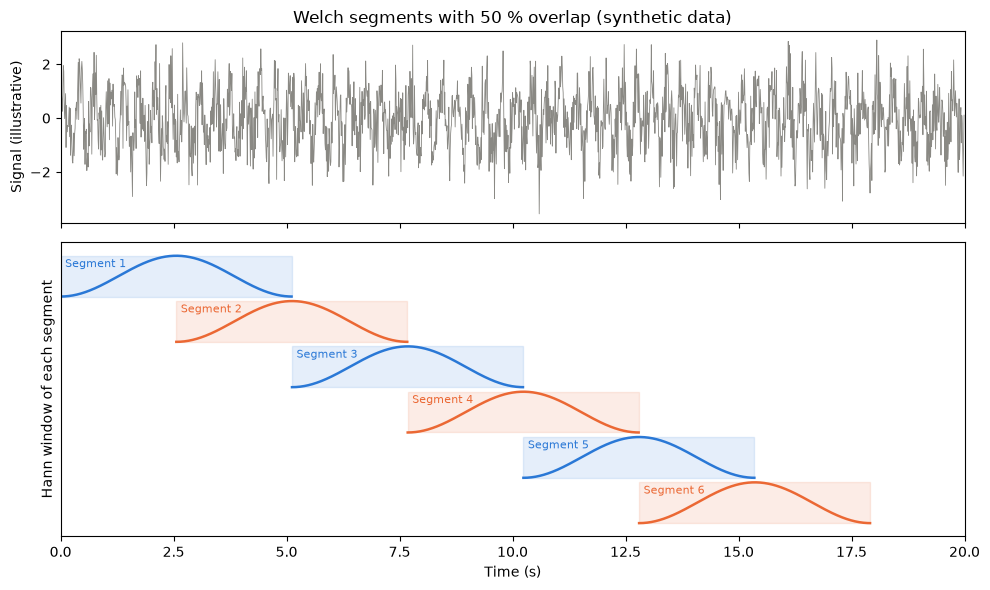

In [6]:
fs = 100.0            # sampling frequency (Hz)
duration = 20.0       # signal length (s)
n_seg = 512           # samples per segment
step = n_seg // 2     # 50 % overlap

rng = np.random.default_rng(0)
t = np.arange(0, duration, 1 / fs)
x = np.sin(2 * np.pi * 3.0 * t) + 0.8 * rng.standard_normal(t.size)

starts = np.arange(0, t.size - n_seg + 1, step)
hann = get_window("hann", n_seg)

fig, (ax_sig, ax_win) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                     gridspec_kw={"height_ratios": [1.3, 2]})
ax_sig.plot(t, x, color="#8a8984", lw=0.6)
ax_sig.set_title("Welch segments with 50 % overlap (synthetic data)")
ax_sig.set_ylabel("Signal (illustrative)")

# One row per segment: shaded span = samples used, curve = Hann window applied to them
for i, s in enumerate(starts):
    row = starts.size - 1 - i
    color = ["#2a78d6", "#eb6834"][i % 2]
    seg_t = t[s:s + n_seg]
    ax_win.axhspan(row, row + 0.9, xmin=seg_t[0] / duration, xmax=seg_t[-1] / duration,
                   color=color, alpha=0.12)
    ax_win.plot(seg_t, row + 0.9 * hann, color=color, lw=1.8)
    ax_win.text(seg_t[0] + 0.1, row + 0.65, f"Segment {i + 1}", fontsize=8, color=color)
ax_win.set_yticks([])
ax_win.set_ylabel("Hann window of each segment")
ax_win.set_xlabel("Time (s)")
ax_win.set_xlim(0, duration)
plt.tight_layout()
plt.show()

Each row is a segment: the band shows the samples it uses and the curve, the Hann window applied to them. Each segment starts halfway through the previous one (50 % overlap), so every instant enters two segments, and the window makes the edges of each segment weigh little.

In Python, `scipy.signal.welch` can be used to compute the PSD.

### **Main uses:**
- Identify the natural frequencies of the structure (the peaks), especially with ambient vibration.
- Estimate the damping from the width of the peaks (half-power bandwidth method).
- Compute cross-PSDs between sensors to obtain the mode shapes (FDD), the FRF and the coherence.
- Monitor changes in the frequencies or in the energy of each mode as a damage indicator.

### **Limitations:**
- Trade-off between resolution and stability: shorter segments give more averages and a smoother spectrum, but the peaks widen ($\Delta f = f_s/N_{seg}$).
- Assumes a stationary signal: if the content changes in time, it loses when it happened (that is what the STFT and wavelets are for).
- Averaging reduces the fluctuation of the estimate, not the noise in the signal.

### **Welch vs. FFT of the whole signal:**
| | FFT of the whole signal | PSD with Welch |
|---|---|---|
| Frequency resolution | Better (separates close peaks) | Lower ($\Delta f = f_s/N_{seg}$) |
| Spectrum stability | Fluctuates a lot and does not improve with longer records | More stable by averaging segments |
| False peaks from noise | Frequent | Fewer; the real peaks stand out better |
| Depends on the record length | Yes (the magnitude changes with the number of samples) | No (normalized per hertz) |
| Coherence and cross-PSDs | Meaningless (with a single block the coherence is 1) | Reliable |

### **Example:**

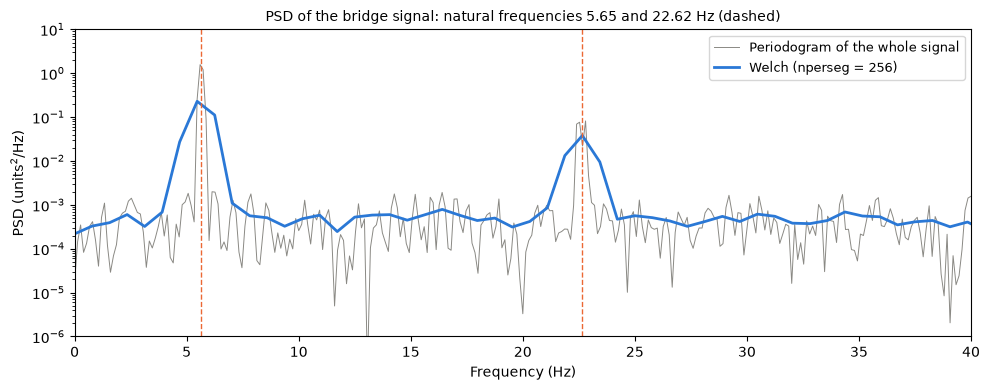

In [7]:
# Colors (same roles as in metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # raw / measured signal (neutral gray)
COLOR_1 = "#2a78d6"        # main series (blue)
COLOR_2 = "#eb6834"        # second series (orange)

# Shared example: vehicle crossing a simply supported bridge
L_SPAN = 15.0         # span (m)
V_SPEED = 2.0         # vehicle speed (m/s)
F1, F2 = 5.65, 22.62  # bridge natural frequencies (Hz)
FS = 200.0            # sampling frequency (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # vehicle position x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # mode 1 shape
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # mode 2 shape

rng = np.random.default_rng(42)   # fixed seed for the noise

# Bridge signal: mode 1 + mode 2 + noise
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.2 * rng.standard_normal(t.size))

f_per, p_per = periodogram(x_bridge, FS, window="hann")        # single FFT of the whole record
f_w, p_w = welch(x_bridge, FS, window="hann", nperseg=256)     # Welch average

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_per, p_per, color=COLOR_SIGNAL, lw=0.7, label="Periodogram of the whole signal")
ax.semilogy(f_w, p_w, color=COLOR_1, lw=2, label="Welch (nperseg = 256)")
for f_n in (F1, F2):
    ax.axvline(f_n, color=COLOR_2, ls="--", lw=1)
ax.set_title("PSD of the bridge signal: natural frequencies 5.65 and 22.62 Hz (dashed)", fontsize=10)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (units$^2$/Hz)")
ax.set_xlim(0, 40)
ax.set_ylim(1e-6, 10)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

The periodogram of the whole signal has narrower peaks, but its noise floor fluctuates a lot. Welch gives a more stable spectrum, at the cost of wider peaks.

<div style="break-before: page; page-break-before: always;"></div>

## 4. Singular Value Decomposition (SVD)

- Developed by Beltrami (1873) and Jordan (1874).
- Covered in CIV E 789, session 8 (Oct 22, 2026), as the basis of the FDD (Lecture 4, slide 29).
- Decomposes any matrix $A$ ($m \times n$) into the product of three matrices:

$$A = U\,\Sigma\,V^T$$

**$U$ ($m \times m$): directions of the axes.** Its columns $\mathbf{u}_i$ are the principal directions of the data, perpendicular to each other.

$$U = \begin{bmatrix} | & | & & | \\ \mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_m \\ | & | & & | \end{bmatrix}$$

**$\Sigma$ ($m \times n$): length of the axes.** It is diagonal; the singular values $\sigma_i$ tell how much each direction weighs and go from largest to smallest.

$$\Sigma = \begin{bmatrix} \sigma_1 & 0 & \cdots & 0 \\ 0 & \sigma_2 & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & \sigma_r \end{bmatrix}, \qquad \sigma_1 \geq \sigma_2 \geq \dots \geq \sigma_r \geq 0$$

**$V^T$ ($n \times n$): how they combine.** Its rows $\mathbf{v}_i^T$ tell how each direction is combined to reconstruct the data.

$$V^T = \begin{bmatrix} \text{---} & \mathbf{v}_1^T & \text{---} \\ \text{---} & \mathbf{v}_2^T & \text{---} \\ & \vdots & \\ \text{---} & \mathbf{v}_n^T & \text{---} \end{bmatrix}$$

- $r$: the number of nonzero singular values (the rank of $A$).

In Python, use `np.linalg.svd(A)`.

### **In structural dynamics:**
If it is applied to the displacement matrix $X$, with one row per sensor ($m$ sensors) and one column per time instant ($N$ instants):

$$X = \begin{bmatrix} x_1(t_1) & x_1(t_2) & \cdots & x_1(t_N) \\ x_2(t_1) & x_2(t_2) & \cdots & x_2(t_N) \\ \vdots & \vdots & \ddots & \vdots \\ x_m(t_1) & x_m(t_2) & \cdots & x_m(t_N) \end{bmatrix}$$

- $x_j(t_k)$: displacement of sensor $j$ at instant $t_k$.

**$U$: the mode shapes.** Each column $\boldsymbol{\phi}_i$ tells how much each sensor moves in mode $i$.

$$U = \begin{bmatrix} | & | & & | \\ \boldsymbol{\phi}_1 & \boldsymbol{\phi}_2 & \cdots & \boldsymbol{\phi}_r \\ | & | & & | \end{bmatrix} = \begin{bmatrix} \phi_{11} & \phi_{12} & \cdots & \phi_{1r} \\ \phi_{21} & \phi_{22} & \cdots & \phi_{2r} \\ \vdots & \vdots & \ddots & \vdots \\ \phi_{m1} & \phi_{m2} & \cdots & \phi_{mr} \end{bmatrix}$$

- $\phi_{ji}$: amplitude of sensor $j$ in mode $i$.

**$\Sigma$: the energy of each mode.** Each $\sigma_i$ tells with how much amplitude mode $i$ vibrates; the one that vibrates the most comes first.

$$\Sigma = \begin{bmatrix} \sigma_1 & & \\ & \ddots & \\ & & \sigma_r \end{bmatrix}$$

**$V^T$: the time history of each mode.** Each row is how mode $i$ varies in time (normalized).

$$V^T = \begin{bmatrix} q_1(t_1) & q_1(t_2) & \cdots & q_1(t_N) \\ q_2(t_1) & q_2(t_2) & \cdots & q_2(t_N) \\ \vdots & \vdots & \ddots & \vdots \\ q_r(t_1) & q_r(t_2) & \cdots & q_r(t_N) \end{bmatrix}$$

- $q_i(t_k)$: value of the coordinate of mode $i$ at instant $t_k$.

Multiplying the three, the response becomes the sum of the modes:

$$X = \sum_{i=1}^{r} \sigma_i\, \boldsymbol{\phi}_i\, \mathbf{q}_i^T$$

This works because the response of a structure is precisely a sum of modes, and the SVD separates them from the measured response, without knowing the stiffness matrix. The FDD uses the same idea, but applied to the PSD matrix of the sensors at each frequency.

### **Limitations:**
- The singular vectors are always perpendicular; the mode shapes are only perpendicular with respect to the mass. If the mass is not uniform or there are very close modes, they do not match exactly.
- In a response matrix, the SVD sorts by energy, not by mode: if two modes vibrate with similar energy, they can mix.

<div style="break-before: page; page-break-before: always;"></div>

## 5. Frequency Domain Decomposition (FDD)

- Proposed by Brincker, Zhang and Andersen (2001) in "Modal identification of output-only systems using frequency domain decomposition" (*Smart Materials and Structures*, 10(3), 441–445).
- Covered in CIV E 789, session 8 (Oct 22, 2026), Lecture 4, slides 29 to 31.
- Identifies the natural frequencies and mode shapes using only the response measured by several sensors (ambient vibration), without knowing the excitation. It assumes the excitation is like white noise.

### **Process:**
1. Compute the PSD matrix of all sensors at each frequency (auto-PSD on the diagonal, cross-PSD off the diagonal).
2. Apply the SVD to the PSD matrix at each frequency.
3. Plot the first singular value against frequency: its peaks are the natural frequencies.
4. At each peak, the first singular vector is the mode shape.

### **Matrices:**
With $m$ sensors, at each frequency $f$ the PSD matrix is built:

$$G(f) = \begin{bmatrix} G_{11}(f) & G_{12}(f) & \cdots & G_{1m}(f) \\ G_{21}(f) & G_{22}(f) & \cdots & G_{2m}(f) \\ \vdots & \vdots & \ddots & \vdots \\ G_{m1}(f) & G_{m2}(f) & \cdots & G_{mm}(f) \end{bmatrix}$$

- $G_{jj}(f)$: PSD of sensor $j$ (diagonal).
- $G_{jk}(f)$: cross-PSD between sensors $j$ and $k$ (off the diagonal).

And it is decomposed with the SVD:

$$G(f) = U(f)\, S(f)\, U(f)^H$$

- $U(f)$: its columns are the singular vectors; near a natural frequency, the first column is the mode shape.

$$U(f) = \begin{bmatrix} | & | & & | \\ \mathbf{u}_1(f) & \mathbf{u}_2(f) & \cdots & \mathbf{u}_m(f) \\ | & | & & | \end{bmatrix}$$

- $S(f)$: diagonal matrix with the singular values $s_1(f) \geq s_2(f) \geq \dots$; each one is the energy of a mode at that frequency.

$$S(f) = \begin{bmatrix} s_1(f) & & \\ & \ddots & \\ & & s_m(f) \end{bmatrix}$$

- $U(f)^H$: the conjugate transpose of $U(f)$ (because the cross-PSDs are complex numbers). Since $G(f)$ is Hermitian, the same $U$ appears on both sides.

Near the natural frequency $f_i$ a single mode dominates, so:

$$G(f_i) \approx s_1(f_i)\, \boldsymbol{\phi}_i\, \boldsymbol{\phi}_i^H$$

- $\boldsymbol{\phi}_i$: the mode shape of mode $i$, equal to the first singular vector $\mathbf{u}_1(f_i)$.

In Python, the PSD matrix is computed with `scipy.signal.csd` for each pair of sensors, and the SVD with `np.linalg.svd`.

### **Main uses:**
- Modal identification with ambient vibration (traffic, wind) on bridges and buildings, without closing the structure or measuring the load.
- Obtain the mode shapes to compute the MAC and compare them between states (intact and damaged).
- Separate modes with close frequencies, which get mixed with peak picking.

### **Limitations:**
- Assumes white-noise excitation: a harmonic (for example, a motor) shows up as a peak that is not a mode.
- Does not give the damping (that is what the EFDD is for).
- The resolution depends on the PSD: very close or highly damped modes are hard to separate.
- Assumes the structure does not change during the measurement.